In [1]:
# %load_ext autoreload
# %autoreload 2
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent.parent.parent.parent.parent
sys.path.insert(0, str(PROJECT_ROOT))
print(PROJECT_ROOT)
from src.inference import generate, encode_cells, get_latent_mean, get_mean, load_data, load_model, sample_around_point, calc_r2_pearson

import scanpy as sc
import os
import anndata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context
import anndata
import seaborn as sns
import torch
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
import scipy.sparse as sp
print("CUDA Available: ", torch.cuda.is_available())
print("Number of GPUs: ", torch.cuda.device_count())


/lustre/work/yaolab/mzhou10/squidiff_practice/Squidiff/project_v3
CUDA Available:  True
Number of GPUs:  1


In [2]:
data = sc.read_h5ad("../experiment/plants_experiment3_predict_process_cluster_7_11/predict_end_cluster_7_11.h5ad")
#data_filtered = data[data.obs["day_types"].isin([14,16,18,20])].copy()
data_filtered = data[data.obs["day_types"].isin([13,14,15,16,17,18,19,20])].copy()
#data_filtered = data.copy()
# print(data)
print(data.obs["weight_types"].unique())
print(data.obs["day_types"].unique())
print(data.obs["cluster_types"].unique())
# print(data.obs["infer_train_mark"].unique())
print("predict filetered data:",data_filtered)
print(data_filtered.obs["weight_types"].unique())
print(data_filtered.obs["day_types"].unique())
print(data_filtered.obs["cluster_types"].unique())
# print(data_filtered.obs["infer_train_mark"].unique())


[0.         0.11111111 0.22222222 0.33333333 0.44444444 0.55555556
 0.66666667 0.77777778 0.88888889 1.        ]
[12. 13. 14. 15. 16. 17. 18. 19. 20. 21.]
[7, 11]
Categories (2, int64): [7, 11]
predict filetered data: AnnData object with n_obs × n_vars = 16000 × 39337
    obs: 'weight_types', 'day_types', 'cluster_types', 'infer_train_mark'
[0.11111111 0.22222222 0.33333333 0.44444444 0.55555556 0.66666667
 0.77777778 0.88888889]
[13. 14. 15. 16. 17. 18. 19. 20.]
[7, 11]
Categories (2, int64): [7, 11]


In [3]:
train_data = sc.read_h5ad("../../input/exp3_train_cluster_0_7_11_adata.h5ad")
print("train original data:", train_data)
train_data.obs["day_types"] = train_data.obs["day"]
train_data.obs["cluster_types"] = train_data.obs["Group"]
train_data.obs.loc[train_data.obs["day"] == 12, "weight_types"] = 0
train_data.obs.loc[train_data.obs["day"] == 21, "weight_types"] = 1

print(train_data.obs["weight_types"].unique())
print(train_data.obs["day_types"].unique())
print(train_data.obs["cluster_types"].unique())

train original data: AnnData object with n_obs × n_vars = 3912 × 39337
    obs: 'n_genes', 'n_counts', 'Cluster', 'leiden_R', 'Cell type', 'Sample_time', 'day', 'Group'
    obsm: 'X_scvi', 'X_umap'
    layers: 'empty', 'normalize_log', 'raw'
[0. 1.]
[12, 21]
Categories (2, int64): [12, 21]
[0, 7, 11]
Categories (3, int64): [0, 7, 11]


In [4]:
import anndata as ad
interp = ad.concat([data_filtered, train_data], axis=0, join="inner")
#new start
interp.X = interp.X.astype("float64")
# interp = interp_all.copy()
#new end
# print(interp_all)
# print(interp_all.obs["weight_types"].unique())
# print(interp_all.obs["day_types"].unique())
# print(interp_all.obs["cluster_types"].unique())
idx = interp.obs.sort_values(["day_types", "cluster_types"]).index
interp_all = interp[idx].copy()
# interp_all = interp_1[interp_1.obs["cluster_types"].sort_values().index].copy()
print(interp_all)
print(interp_all.obs["weight_types"].unique())
print(interp_all.obs["day_types"].unique())
print(interp_all.obs["cluster_types"].unique())

/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/anndata/_core/merge.py:1111: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


AnnData object with n_obs × n_vars = 19912 × 39337
    obs: 'weight_types', 'day_types', 'cluster_types'
[0.         0.11111111 0.22222222 0.33333333 0.44444444 0.55555556
 0.66666667 0.77777778 0.88888889 1.        ]
[12. 13. 14. 15. 16. 17. 18. 19. 20. 21.]
[0, 7, 11]
Categories (3, int64): [0, 7, 11]


computing PCA
    with n_comps=50
    finished (0:03:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:16)
computing Diffusion Maps using n_comps=15(=n_dcs)
computing transitions
    finished (0:00:00)
    eigenvalues of transition matrix
    [1.         0.99618995 0.9945782  0.993702   0.9875401  0.9852412
     0.9836363  0.9785607  0.97723293 0.9731188  0.96806127 0.9663548
     0.96235377 0.95926183 0.9569494 ]
    finished: added
    'X_diffmap', diffmap coordinates (adata.obsm)
    'diffmap_evals', eigenvalues of transition matrix (adata.uns) (0:00:00)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:02)
running PAGA
    finished: added

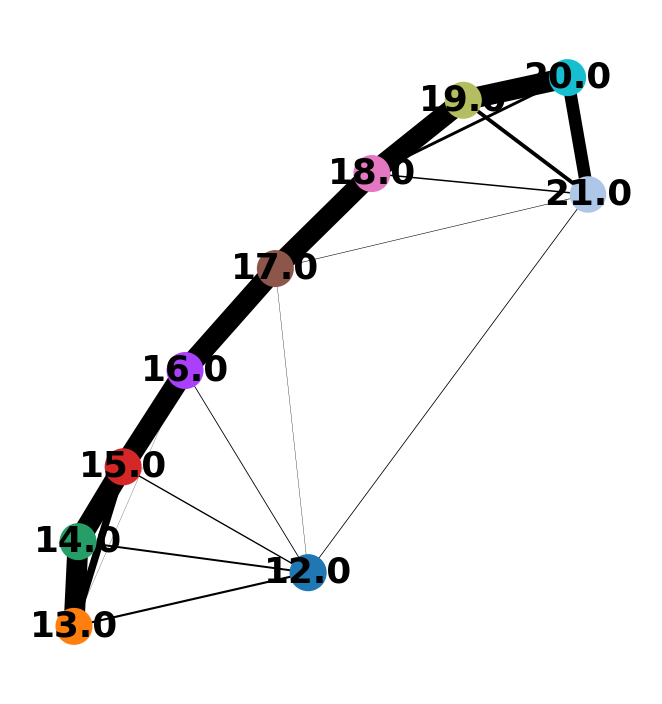

computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm) (0:00:16)
Root cells: 2026
computing Diffusion Pseudotime using n_dcs=10
    finished: added
    'dpt_pseudotime', the pseudotime (adata.obs) (0:00:00)


In [ ]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.verbosity = 3
sc.settings.set_figure_params(
    dpi=100,
    frameon=False,
    figsize=(4, 4),
    facecolor="white"
)
interp_all_ann = interp_all.copy()

# cluster_types used for embedding_density grouping
interp_all_ann.obs["cluster_types"] = (
    interp_all_ann.obs["cluster_types"]
    .astype(str)
    .astype("category")
)

# day_types used for PAGA trajectory
interp_all_ann.obs["day_types"] = pd.to_numeric(interp_all_ann.obs["day_types"])
interp_all_ann.obs["day_types"] = interp_all_ann.obs["day_types"].astype("category")
# PCA
#original
# sc.pp.pca(interp_all_ann)
sc.tl.pca(interp_all_ann, svd_solver="arpack")
sc.pp.neighbors(interp_all_ann, n_neighbors=15, n_pcs=30)
# sc.pp.neighbors(interp_all_ann)
# # First neighbor graph
# sc.pp.neighbors(
#     interp_all_ann,
#     n_neighbors=10,
#     n_pcs=20
# )
# sc.tl.umap(interp_all_ann)
# Optional diffusion-map denoising
sc.tl.diffmap(interp_all_ann)
sc.pp.neighbors(interp_all_ann)
# sc.pp.neighbors(
#     interp_all_ann,
#     n_neighbors=10,
#     use_rep="X_diffmap"
# )

# PAGA using day_types
sc.tl.paga(interp_all_ann, groups="day_types")

sc.pl.paga(
    interp_all_ann,
    color=["day_types"]
)

# UMAP initialized by PAGA
# sc.tl.umap(
#     interp_all_ann,
#     init_pos="paga",
#     random_state=0
# )
sc.tl.umap(interp_all_ann)


# Choose root from starting day
root_day = 12   # change to 12 if numeric, or another starting day

root_mask = interp_all_ann.obs["day_types"] == root_day

print("Root cells:", root_mask.sum())

interp_all_ann.uns["iroot"] = np.flatnonzero(root_mask)[0]

# DPT pseudotime
sc.tl.dpt(interp_all_ann)

# # Scale to 0-1
# pt = interp_all_ann.obs["dpt_pseudotime"]

# interp_all_ann.obs["pseudotime_0_1"] = (
#     (pt - pt.min()) / (pt.max() - pt.min())
# )



AAACGAAAGCGCAATG-1-batch-nodule_small    False
AAACGAAAGTAGGAAG-1-batch-nodule_small    False
AAACGCTCACATGACT-1-batch-nodule_small    False
AAACGCTTCTTGTGCC-1-batch-nodule_small    False
AAAGAACAGGTCATAA-1-batch-nodule_small    False
                                         ...  
TTTACGTCAGATACTC-1-batch-nodule_large    False
TTTACTGGTGTGAATA-1-batch-nodule_large    False
TTTCAGTAGCTGTACT-1-batch-nodule_large    False
TTTCAGTAGGTTCATC-1-batch-nodule_large    False
TTTCAGTCATTGAGGG-1-batch-nodule_large    False
Length: 19912, dtype: bool


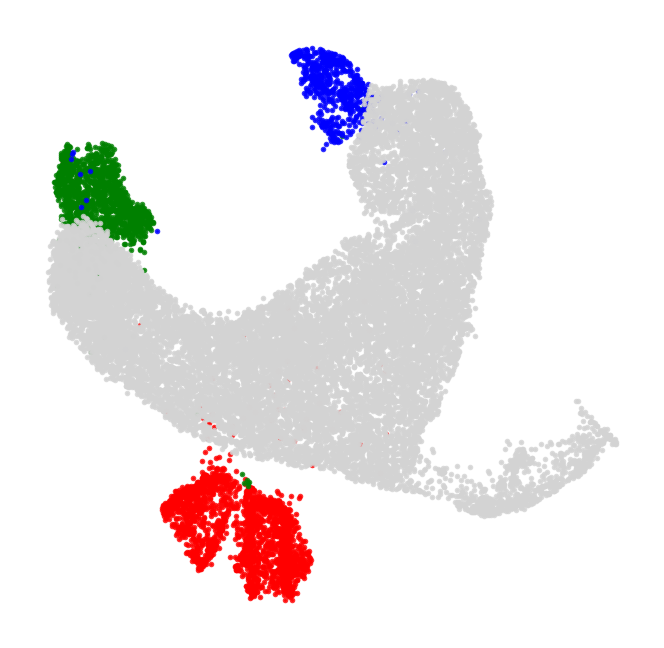

In [6]:
fig,ax = plt.subplots(figsize=(4, 4))
X_umap = interp_all_ann.obsm["X_umap"]

mask_12 = interp_all_ann.obs["day_types"] == 12

mask_21_7 = (
    (interp_all_ann.obs["day_types"] == 21) &
    (interp_all_ann.obs["cluster_types"] == '7')
)

print(mask_21_7)
mask_21_11 = (
    (interp_all_ann.obs["day_types"] == 21) &
    (interp_all_ann.obs["cluster_types"] == '11')
)

mask_other = ~interp_all_ann.obs["day_types"].isin([12, 21])

plt.scatter(
    X_umap[mask_12, 0],
    X_umap[mask_12, 1],
    c="red",
    s=1,
    alpha=0.8,
    label="day 12"
)

plt.scatter(
    X_umap[mask_21_7, 0],
    X_umap[mask_21_7, 1],
    c="green",
    s=1,
    alpha=0.8,
    label="day 21 cluster 7"
)

plt.scatter(
    X_umap[mask_21_11, 0],
    X_umap[mask_21_11, 1],
    c="blue",
    s=1,
    alpha=0.8,
    label="day 21 cluster 11"
)

plt.scatter(
    X_umap[mask_other, 0],
    X_umap[mask_other, 1],
    c="lightgray",
    s=1,
    alpha=0.8,
    label="other days"
)

plt.axis("off")
# plt.title("combined umap marked training data")
fig.savefig(os.path.join(f"exp3_umap_with_training_data_cells_order_change.pdf"), bbox_inches="tight")
# plt.legend()
plt.show()



View of AnnData object with n_obs × n_vars = 2000 × 39337
    obs: 'weight_types', 'day_types', 'cluster_types', 'dpt_pseudotime'
    uns: 'pca', 'neighbors', 'diffmap_evals', 'paga', 'day_types_sizes', 'day_types_colors', 'umap', 'iroot'
    obsm: 'X_pca', 'X_diffmap', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
     cluster_types day_types  dpt_pseudotime
1000             7      13.0        0.220228
1001             7      13.0        0.233445
1002             7      13.0        0.245361
1003             7      13.0        0.263251
1004             7      13.0        0.235447


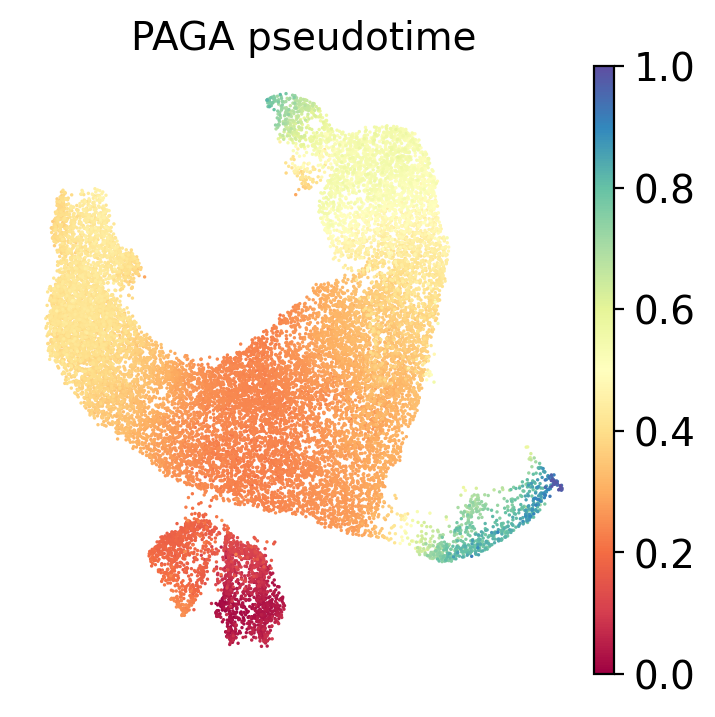

In [7]:

# fig = plt.subplots(figsize=(4, 4))
sc.pl.umap(
    interp_all_ann,
    color=["dpt_pseudotime"],
    cmap="Spectral",
    title="PAGA pseudotime",
    na_color="black",
    show=False
)
mask_13 = interp_all_ann.obs["day_types"] == 13
print(interp_all_ann[mask_13])
print(interp_all_ann.obs.loc[mask_13, ["cluster_types", "day_types","dpt_pseudotime"]].head())
fig = plt.gcf()
fig.savefig(os.path.join(f"exp3_paga_0to1_cells_order_change.pdf"), bbox_inches="tight")
plt.show()

computing density on 'umap'
--> added
    'umap_density_cluster_types', densities (adata.obs)
    'umap_density_cluster_types_params', parameter (adata.uns)
Index(['0', '11', '7'], dtype='object')
plotting group: 0
plotting group: 11
plotting group: 7


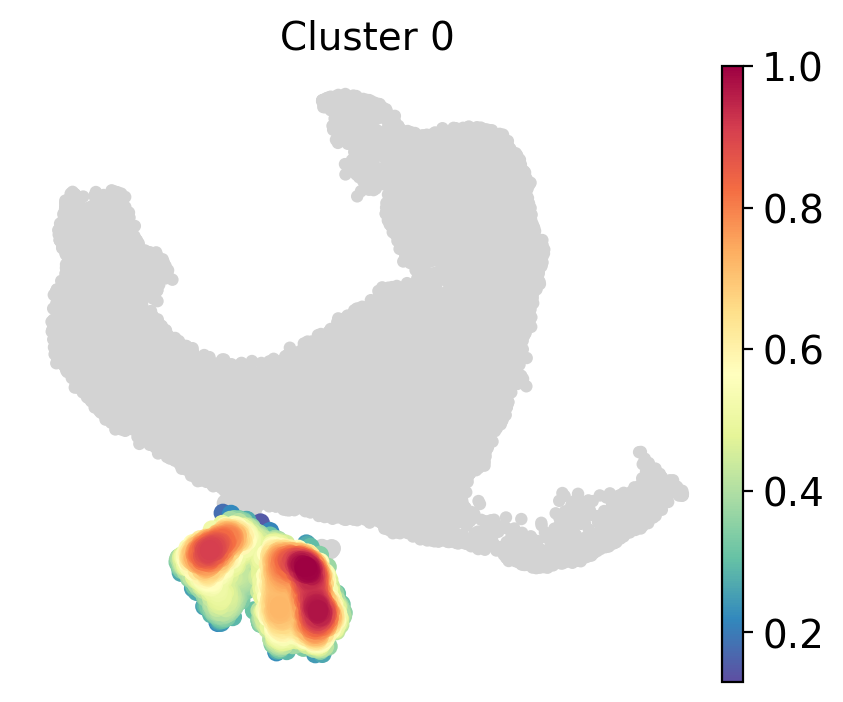

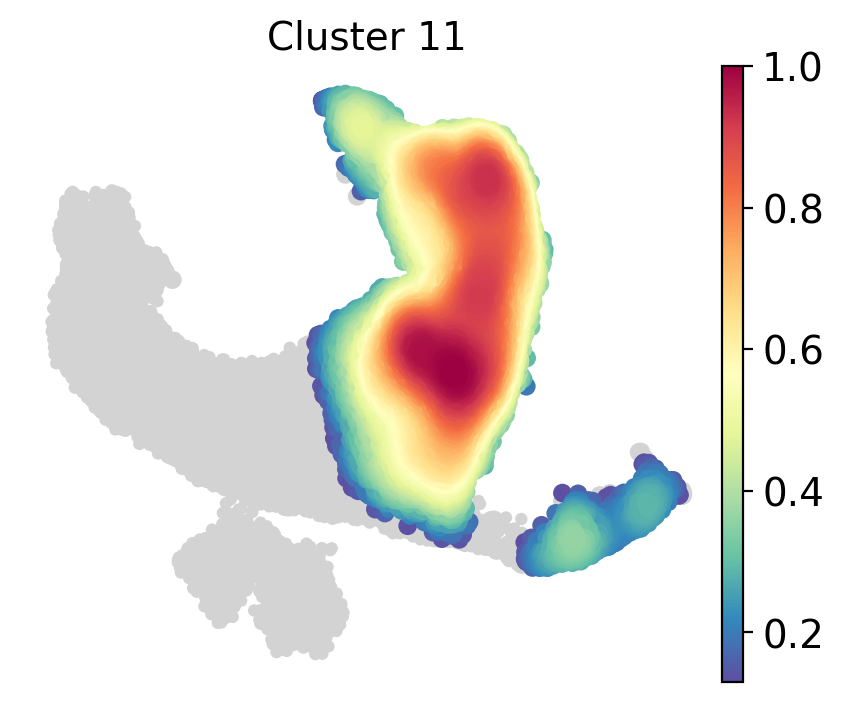

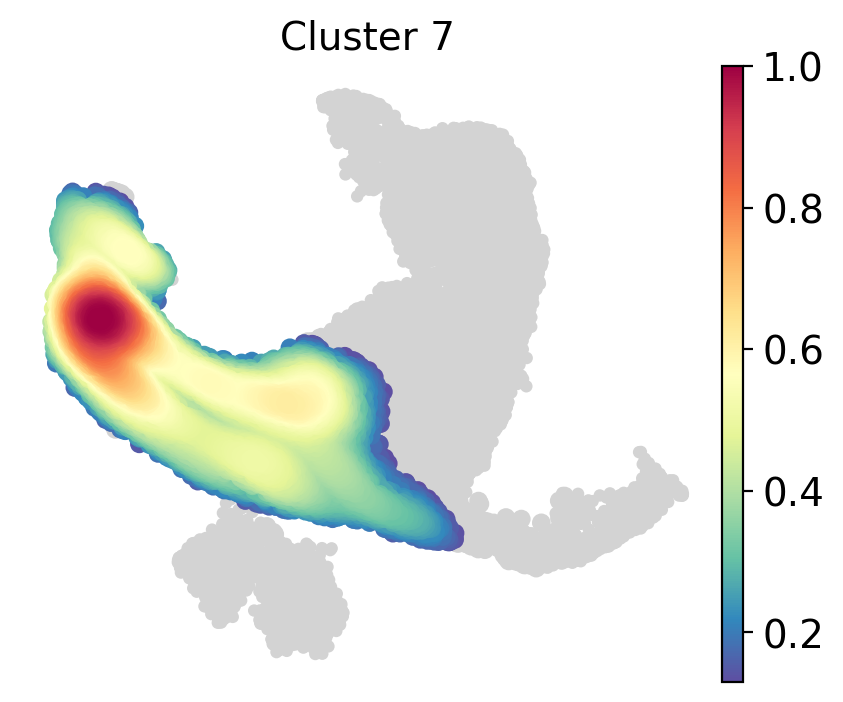

In [8]:
sc.tl.embedding_density(
    interp_all_ann,
    basis="umap",
    groupby="cluster_types"
)
# draw embedding density like your example
groups = interp_all_ann.obs["cluster_types"].cat.categories[:3]
print(groups)
for g in groups:
    g = str(g)
    print("plotting group:", g)

    sc.pl.embedding_density(
        interp_all_ann,
        basis="umap",
        groupby="cluster_types",
        group=g,
        color_map="Spectral_r",
        vmin=0.13,
        title=f"Cluster {g}",
        show=False
    )

    plt.savefig(
        os.path.join(f"umap_density_cluster_{g}_cells_order_change.pdf"),
        bbox_inches="tight"
    )


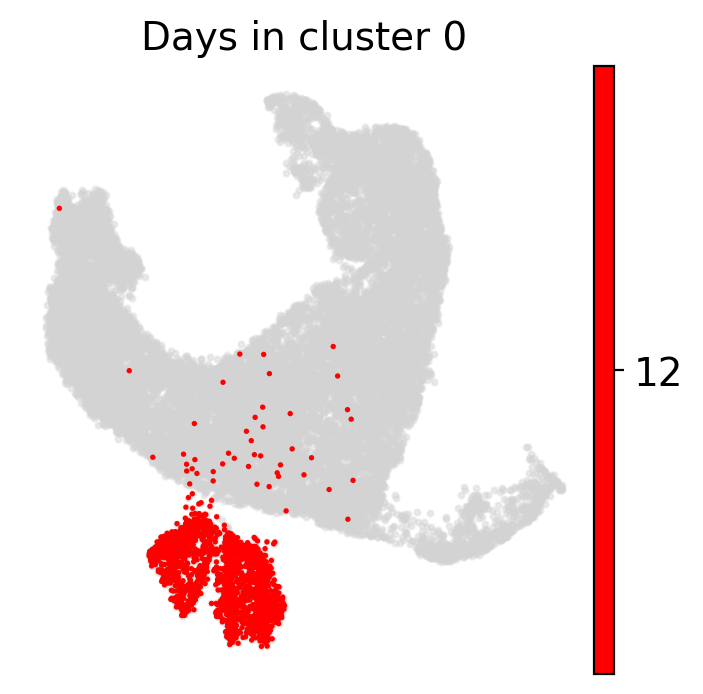

/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


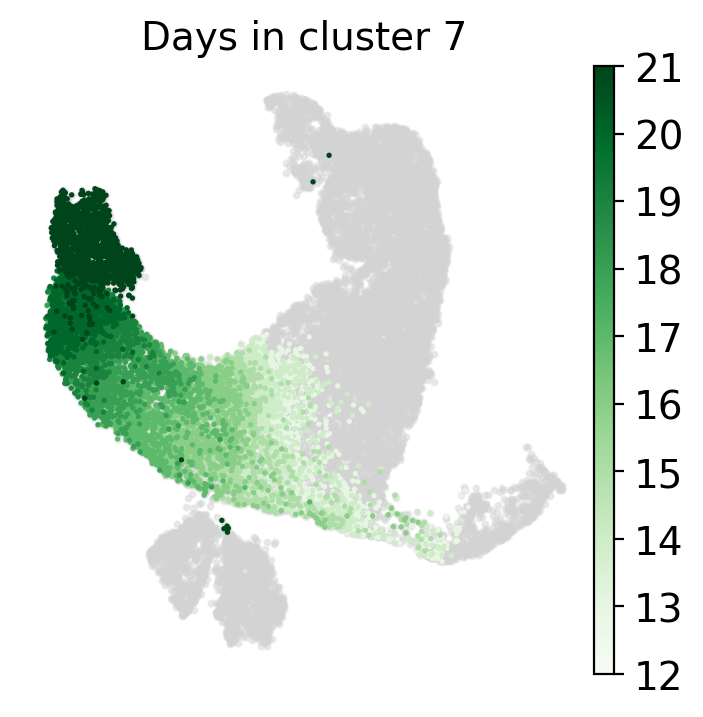

/home/yaolab/mzhou10/.conda/envs/cdecoder/lib/python3.8/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  cax = scatter(


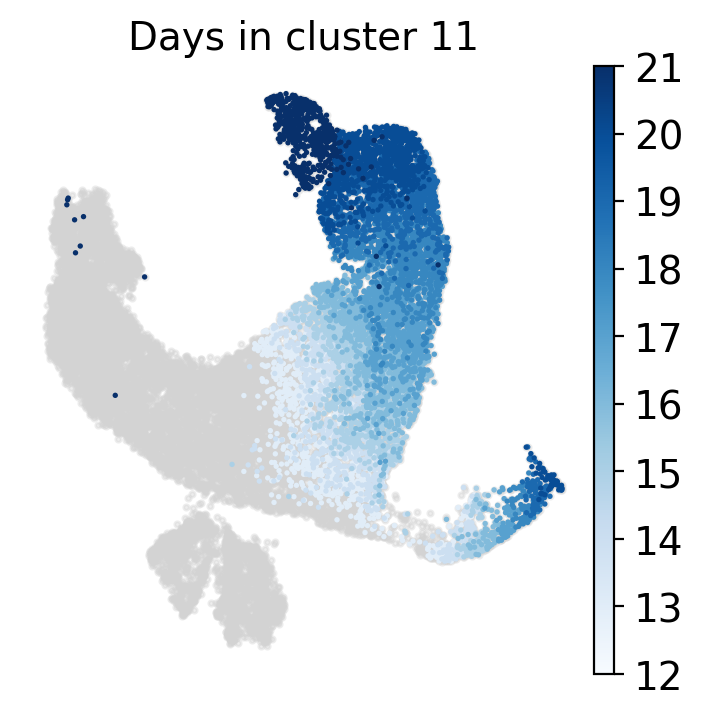

In [10]:
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import matplotlib.colors as mcolors

# make sure day_types is numeric
interp_all_ann.obs["day_types_num"] = pd.to_numeric(
    interp_all_ann.obs["day_types"]
)

# cluster settings
cluster_settings = {
    "0": {
        "cmap": "Reds",
        "title": "Days in cluster 0",
        "filename": "umap_days_cluster_0_cells_order_change.pdf"
    },
    "7": {
        "cmap": "Greens",
        "title": "Days in cluster 7",
        "filename": "umap_days_cluster_7_cells_order_change.pdf"
    },
    "11": {
        "cmap": "Blues",
        "title": "Days in cluster 11",
        "filename": "umap_days_cluster_11_cells_order_change.pdf"
    }
}

for cluster_id, setting in cluster_settings.items():
    
    fig, ax = plt.subplots(figsize=(4, 4))

    # 1. plot all cells as gray background
    sc.pl.umap(
        interp_all_ann,
        color=None,
        ax=ax,
        frameon=False,
        title="",
        size=15,
        show=False
    )

    # make background cells gray
    ax.collections[0].set_color("lightgray")
    ax.collections[0].set_alpha(0.4)
    one_color_cmap = mcolors.ListedColormap(["red"])
    # 2. overlay one cluster colored by day_types_num
    mask = interp_all_ann.obs["cluster_types"] == cluster_id
    if cluster_id =="0":
        sc.pl.umap(
                interp_all_ann[mask],
                color="day_types_num",
                # vmin=12,
                # vmax=21,
                ax=ax,
                frameon=False,
                title=setting["title"],
                size=15,
                cmap=one_color_cmap,
                show=False
            )

        # ax.collections[-1].set_color("red")
    else:
        sc.pl.umap(
            interp_all_ann[mask],
            color="day_types_num",
            vmin=12,
            vmax=21,
            ax=ax,
            frameon=False,
            title=setting["title"],
            size=15,
            cmap=setting["cmap"],
            show=False
        )
    if cluster_id =="0":
        cbar = ax.collections[-1].colorbar
        cbar.set_ticks([12])
        cbar.set_ticklabels(["12"])
    else:
        cbar = ax.collections[-1].colorbar
        cbar.set_ticks(range(12, 22))
        cbar.set_ticklabels([str(i) for i in range(12, 22)])
    # save figure
    fig.savefig(setting["filename"], bbox_inches="tight")

    plt.show()
    plt.close(fig)

    pseudotime_point cluster_types  cell_number
0               0.00             0            1
3               0.01             0           46
6               0.02             0          109
9               0.03             0          202
12              0.04             0          144
    pseudotime_point cluster_types  cell_number  accumulated_cell_number
0               0.00             0            1                        1
3               0.01             0           46                       47
6               0.02             0          109                      156
9               0.03             0          202                      358
12              0.04             0          144                      502
cat categories: Index(['0', '11', '7'], dtype='object')


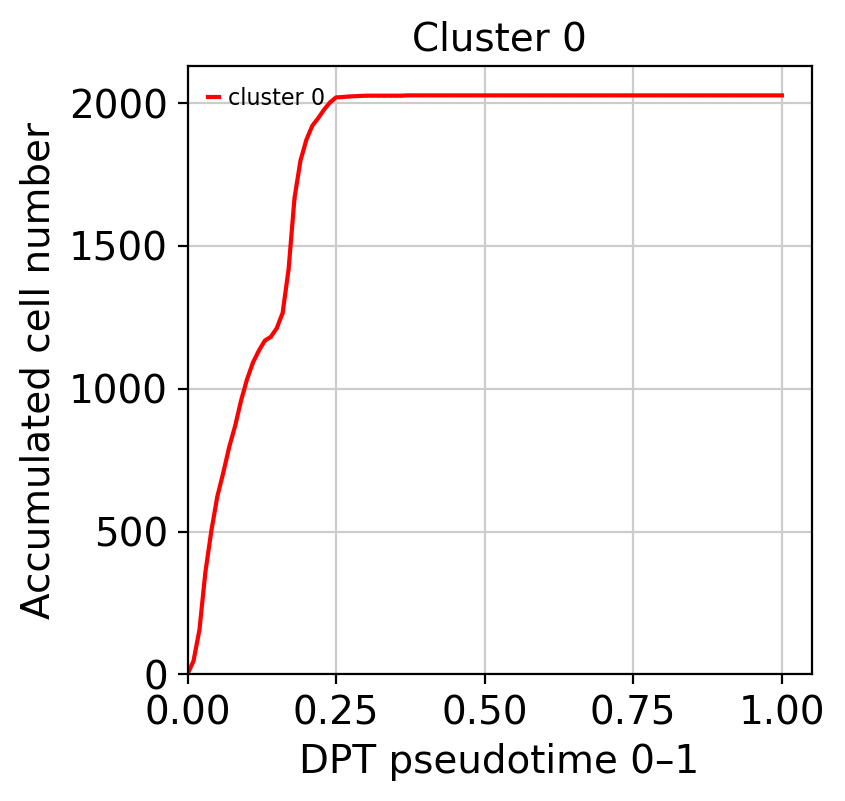

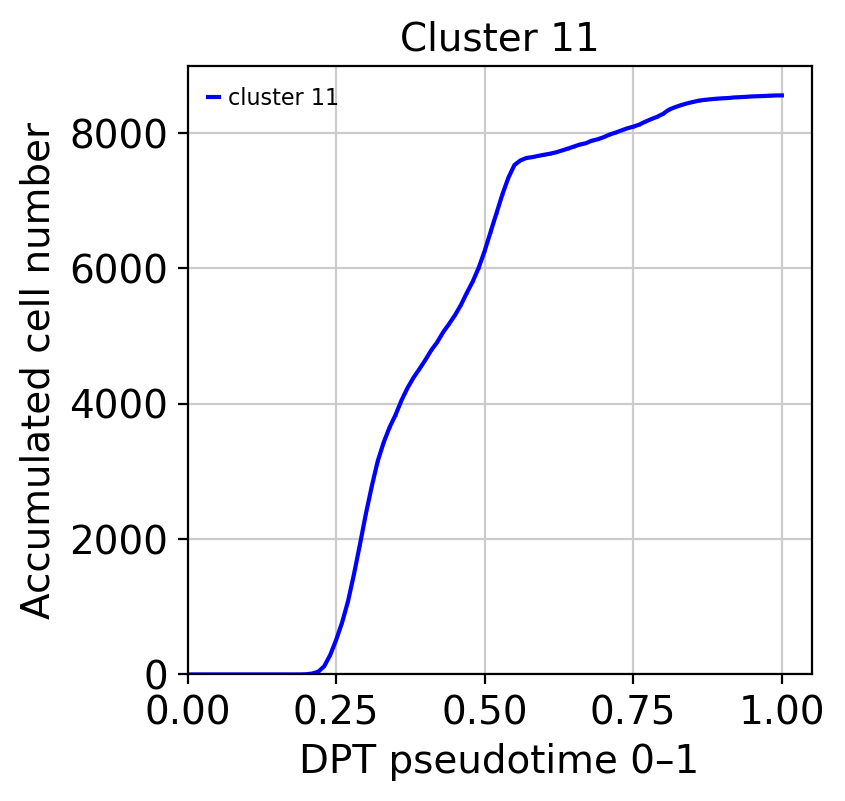

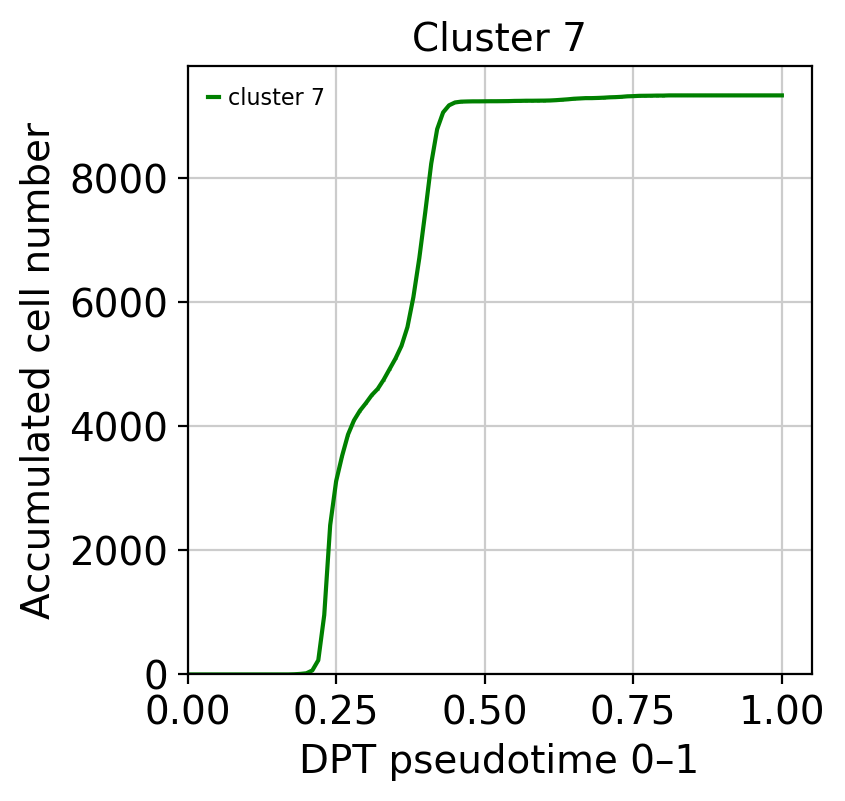

In [ ]:
adata = interp_all_ann.copy()
adata.obs["pseudotime_point"] = adata.obs["dpt_pseudotime"].round(2)

count_df = (
    adata.obs
    .groupby(["pseudotime_point", "cluster_types"], observed=False)
    .size()
    .reset_index(name="cell_number")
)

# Sort for plotting
count_df = count_df.sort_values(["cluster_types", "pseudotime_point"])

print(count_df.head())
count_df["accumulated_cell_number"] = (
    count_df
    .groupby("cluster_types", observed=False)["cell_number"]
    .cumsum()
)

print(count_df.head())


print("cat categories:",adata.obs["cluster_types"].cat.categories)
# one figure for each cluster
cluster_colors = {
    "0": "red",
    "7": "green",
    "11": "blue"
}
for clust in adata.obs["cluster_types"].cat.categories:

    tmp = count_df[count_df["cluster_types"] == clust].copy()
    tmp = tmp.sort_values("pseudotime_point")

    fig, ax = plt.subplots(figsize=(4, 4))

    ax.plot(
        tmp["pseudotime_point"],
        tmp["accumulated_cell_number"],
        marker="o",
        linewidth=1.5,
        markersize=0.1,
        color=cluster_colors[str(clust)],
        label=f"cluster {clust}"
    )

    ax.set_xlabel("DPT pseudotime 0–1")
    ax.set_ylabel("Accumulated cell number")
    ax.set_title(f"Cluster {clust}")

    ax.legend(
        loc="upper left",
        frameon=False,
        fontsize=8
    )
    ax.set_ylim(bottom=0)
    ax.set_xlim(left=0)
    fig.savefig(
        os.path.join(f"exp3_accumulated_density_cluster_{clust}_cells_order_change.pdf"),
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

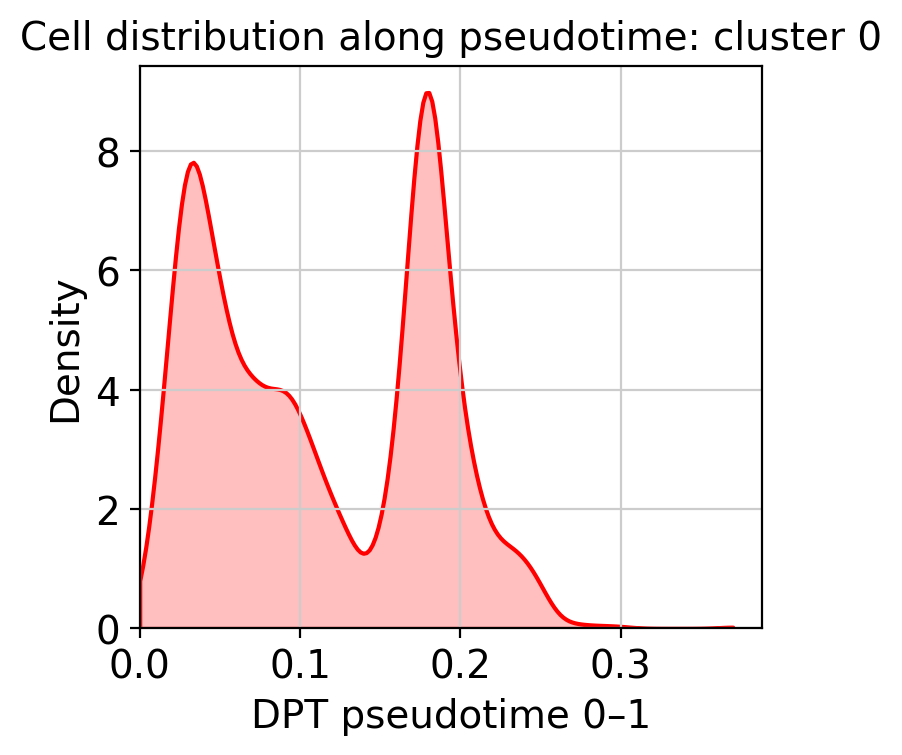

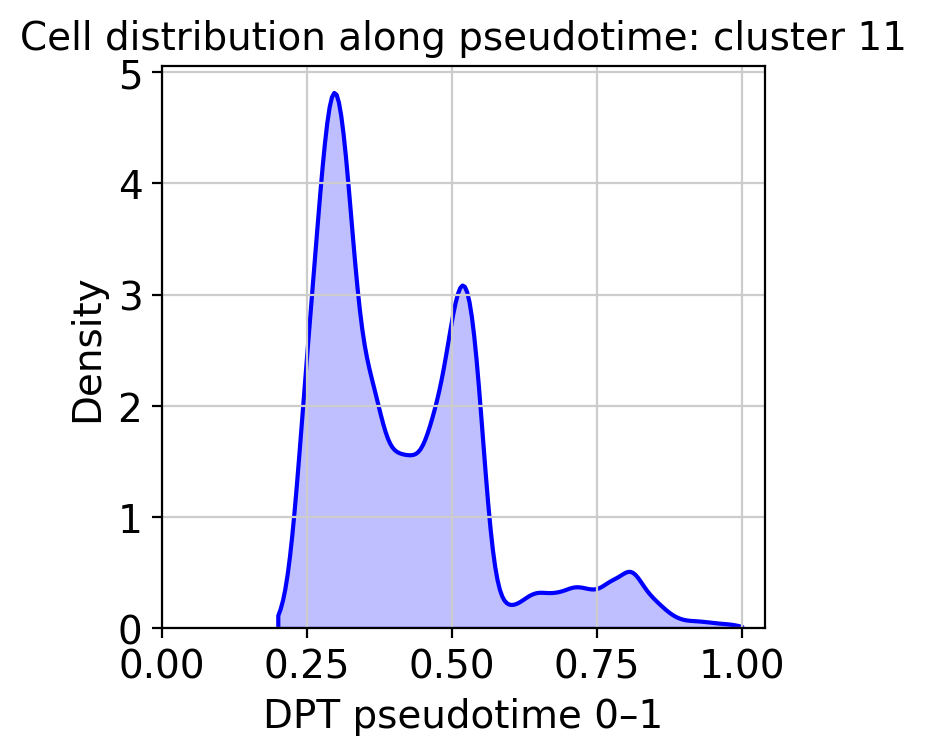

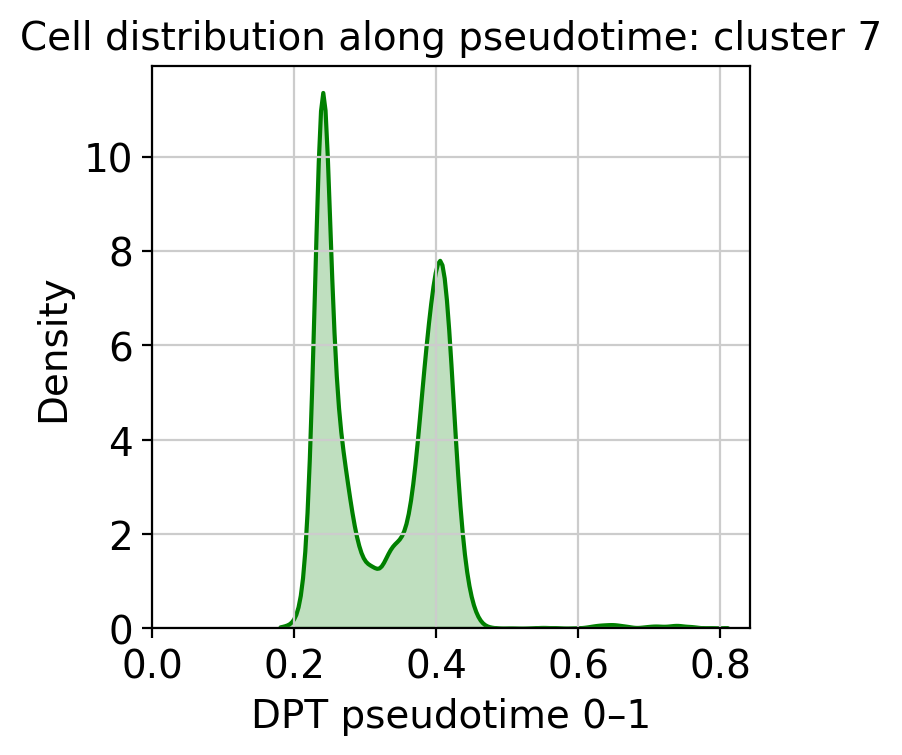

In [ ]:

plot_df = adata.obs[
    ["pseudotime_point", "cluster_types"]
].dropna().copy()

plot_df["cluster_types"] = plot_df["cluster_types"].astype(str)


for clust in adata.obs["cluster_types"].cat.categories:
    
    tmp = plot_df[plot_df["cluster_types"] == clust].copy()
    tmp = tmp.sort_values("pseudotime_point")

    fig, ax = plt.subplots(figsize=(4, 4))

    sns.kdeplot(
        data=tmp,                       # only this cluster
        x="pseudotime_point",
        common_norm=False,
        bw_adjust=0.6,
        cut=0,
        clip=(0, 1),
        fill=True,
        alpha=0.25,
        linewidth=1.5,
        color=cluster_colors[str(clust)],
        ax=ax
    )

    ax.set_xlabel("DPT pseudotime 0–1")
    ax.set_ylabel("Density")
    ax.set_title(f"Cell distribution along pseudotime: cluster {clust}")
    ax.set_xlim(left=0)
    # x_start = tmp['pseudotime_point'].min()
    # ax.set_xticks(sorted([x_start] + list(ax.get_xticks())))
    # ax.margins(x=0, y=0)
    plt.tight_layout()
    plt.savefig(
        f"density_pseudotime_cluster_{clust}_cells_order_change.pdf",
        bbox_inches="tight",
        dpi=300
    )
    plt.show()
    plt.close(fig)

                                       weight_types day_types cluster_types  \
AAACGAAAGCGCAATG-1-batch-nodule_small           0.0      12.0             0   
AAACGAAAGTAGGAAG-1-batch-nodule_small           0.0      12.0             0   
AAACGCTCACATGACT-1-batch-nodule_small           0.0      12.0             0   
AAACGCTTCTTGTGCC-1-batch-nodule_small           0.0      12.0             0   
AAAGAACAGGTCATAA-1-batch-nodule_small           0.0      12.0             0   
...                                             ...       ...           ...   
TTTACGTCAGATACTC-1-batch-nodule_large           1.0      21.0            11   
TTTACTGGTGTGAATA-1-batch-nodule_large           1.0      21.0            11   
TTTCAGTAGCTGTACT-1-batch-nodule_large           1.0      21.0            11   
TTTCAGTAGGTTCATC-1-batch-nodule_large           1.0      21.0            11   
TTTCAGTCATTGAGGG-1-batch-nodule_large           1.0      21.0            11   

                                       dpt_pseudoti

/tmp/ipykernel_1035552/2315978782.py:26: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(


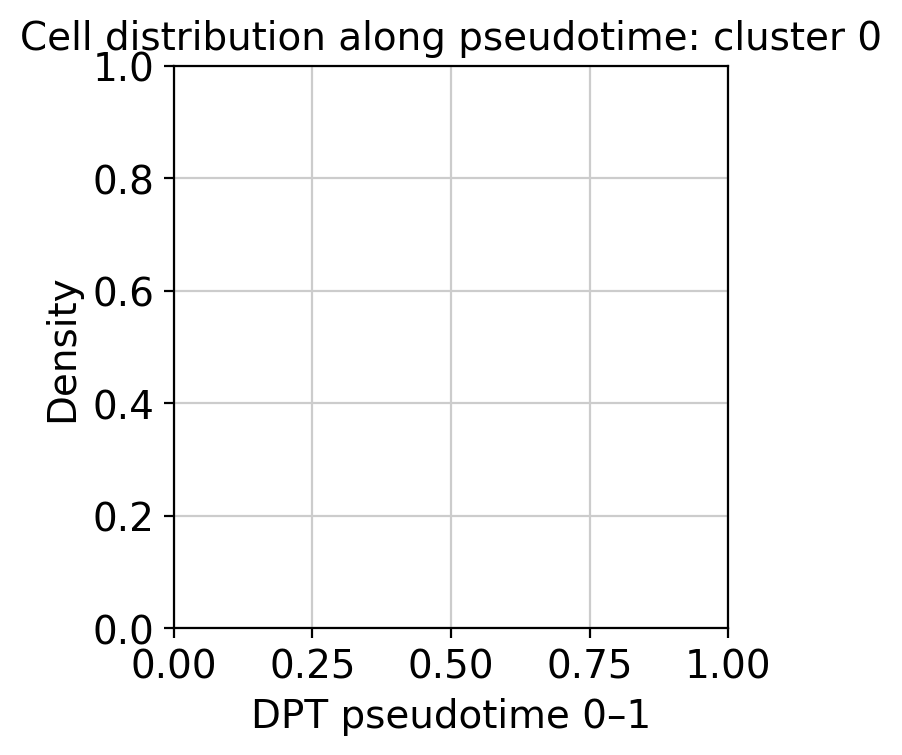

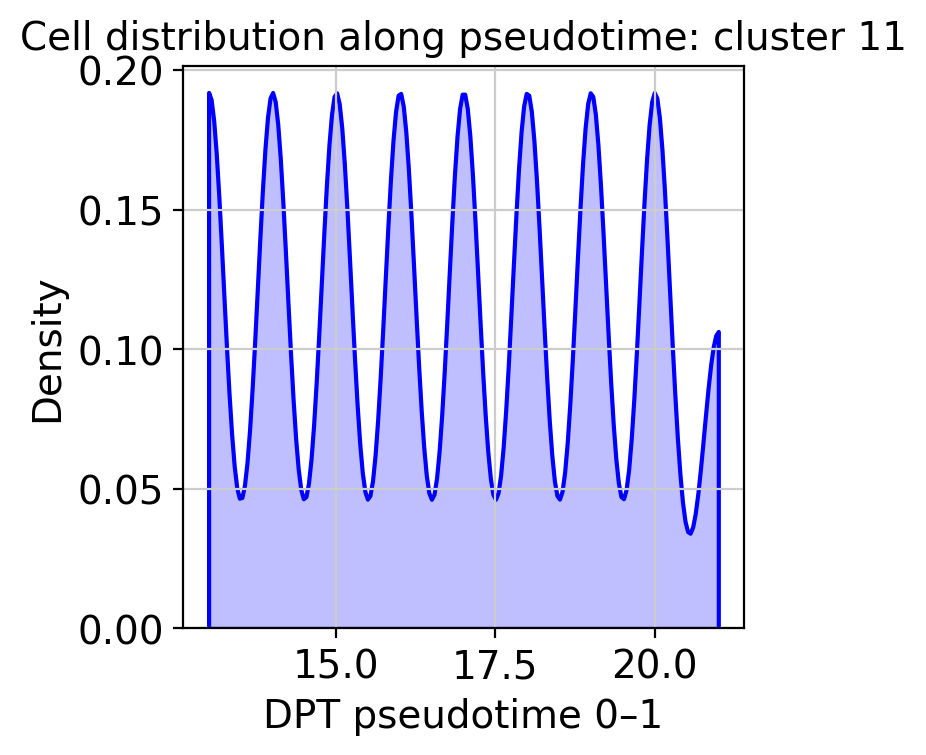

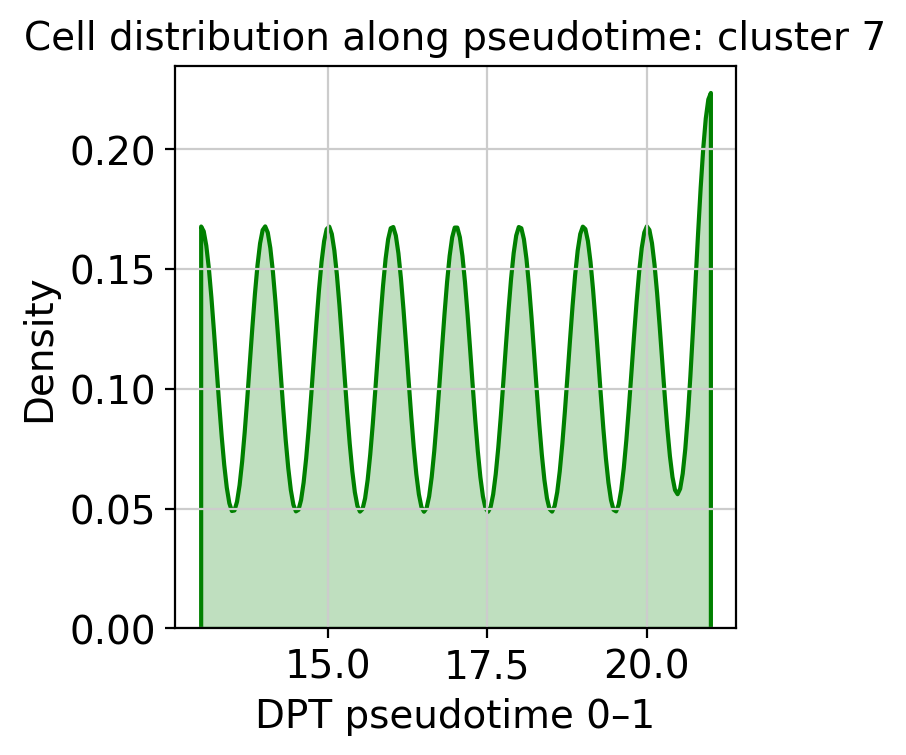

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# adata = interp_all_ann.copy()
# print(adata.obs)
# # count_df = (
# #     adata.obs
# #     .groupby(["day_types", "cluster_types"], observed=False)
# #     .size()
# #     .reset_index(name="cell_number")
# # )

# plot_df = adata.obs[
#     ["day_types", "cluster_types"]
# ].dropna().copy()
# print(plot_df)
# plot_df["cluster_types"] = plot_df["cluster_types"].astype(str)
# plot_df["day_types_num"] = pd.to_numeric(plot_df["day_types"])

# for clust in adata.obs["cluster_types"].cat.categories:

#     tmp = plot_df[plot_df["cluster_types"] == clust].copy()
#     tmp = tmp.sort_values("day_types_num")

#     fig, ax = plt.subplots(figsize=(4, 4))

#     sns.kdeplot(
#         data=tmp,                       # only this cluster
#         x="day_types_num",
#         common_norm=False,
#         bw_adjust=0.6,
#         cut=0,
#         clip=(12, 21),
#         fill=True,
#         alpha=0.25,
#         linewidth=1.5,
#         color=cluster_colors[str(clust)],
#         ax=ax
#     )

#     ax.set_xlabel("DPT pseudotime 0–1")
#     ax.set_ylabel("Density")
#     ax.set_title(f"Cell distribution along pseudotime: cluster {clust}")

#     plt.tight_layout()
#     plt.savefig(
#         f"density_pseudotime_cluster_{clust}_cells_order_change.pdf",
#         bbox_inches="tight",
#         dpi=300
#     )
#     plt.show()
#     plt.close(fig)